In [16]:
# # RetailPulse — Step 8
# # Inventory Optimization & Inventory Risk Analysis

# This notebook performs product-level inventory analysis using historical
# demand data.

# Objectives:
# 1. Analyze product demand
# 2. Calculate demand variability
# 3. Calculate lead-time demand
# 4. Calculate safety stock
# 5. Calculate reorder point
# 6. Perform ABC classification
# 7. Calculate modeled inventory risk
# 8. Generate inventory optimization outputs 

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

from pathlib import Path

In [18]:
PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
OUTPUTS_DIR = REPORTS_DIR / "outputs"

MODELS_DIR = PROJECT_ROOT / "models"

# Create directories if they do not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directories ready.")

Project directories ready.


In [19]:
product_demand_path = PROCESSED_DIR / "product_daily_demand.csv"

product_demand = pd.read_csv(product_demand_path)

print("Shape:", product_demand.shape)
print("\nColumns:")
print(product_demand.columns.tolist())

product_demand.head()

Shape: (439167, 10)

Columns:
['Date', 'StockCode', 'QuantitySold', 'Revenue', 'Orders', 'Customers', 'DemandRolling7', 'DemandRolling30', 'DemandLag1', 'DemandLag7']


C:\Users\iamde\AppData\Local\Temp\ipykernel_23056\518502541.py:3: DtypeWarning: Columns (1: StockCode) have mixed types. Specify dtype option on import or set low_memory=False.
  product_demand = pd.read_csv(product_demand_path)


,Date,StockCode,QuantitySold,Revenue,Orders,Customers,DemandRolling7,DemandRolling30,DemandLag1,DemandLag7
0,2009-12-01,10002,12,10.20,1,1,12.000000,12.000000,NaN,NaN
1,2009-12-03,10002,6,5.10,3,3,9.000000,9.000000,12.0,NaN
2,2009-12-04,10002,73,62.05,4,4,30.333333,30.333333,6.0,NaN
3,2009-12-06,10002,49,41.65,2,2,35.000000,35.000000,73.0,NaN
4,2009-12-07,10002,2,1.70,1,1,28.400000,28.400000,49.0,NaN


In [20]:
product_demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 439167 entries, 0 to 439166
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date             439167 non-null  str    
 1   StockCode        439167 non-null  object 
 2   QuantitySold     439167 non-null  int64  
 3   Revenue          439167 non-null  float64
 4   Orders           439167 non-null  int64  
 5   Customers        439167 non-null  int64  
 6   DemandRolling7   439167 non-null  float64
 7   DemandRolling30  439167 non-null  float64
 8   DemandLag1       434536 non-null  float64
 9   DemandLag7       408927 non-null  float64
dtypes: float64(5), int64(3), object(1), str(1)
memory usage: 37.7+ MB


In [21]:
product_demand.describe(include="all")

,Date,StockCode,QuantitySold,Revenue,Orders,Customers,DemandRolling7,DemandRolling30,DemandLag1,DemandLag7
count,439167,439167,439167.000000,439167.000000,439167.000000,439167.000000,439167.000000,439167.000000,434536.000000,408927.000000
unique,604,4633,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2011-12-05,85123A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1408,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,23.940669,39.563092,1.750735,1.735497,24.240216,24.863509,23.725551,23.954050
std,NaN,NaN,197.037253,309.887206,1.380172,1.345355,190.773377,191.605404,152.970918,150.556388
min,NaN,NaN,1.000000,0.001000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,NaN,NaN,3.000000,6.950000,1.000000,1.000000,6.142857,7.633333,3.000000,3.000000
50%,NaN,NaN,9.000000,15.800000,1.000000,1.000000,12.571429,14.900000,9.000000,9.000000
75%,NaN,NaN,24.000000,34.000000,2.000000,2.000000,26.142857,28.100000,24.000000,24.000000


In [22]:
product_demand.isnull().sum()

Date                   0
StockCode              0
QuantitySold           0
Revenue                0
Orders                 0
Customers              0
DemandRolling7         0
DemandRolling30        0
DemandLag1          4631
DemandLag7         30240
dtype: int64

In [23]:
# Standardize the columns

# Because your earlier notebook may have created slightly different column names, let's make this step robust.




In [24]:
print(product_demand.columns.tolist())

['Date', 'StockCode', 'QuantitySold', 'Revenue', 'Orders', 'Customers', 'DemandRolling7', 'DemandRolling30', 'DemandLag1', 'DemandLag7']


In [25]:
product_demand = product_demand.rename(
    columns={
        "Quantity": "DailyQuantity"
    }
)

In [26]:
print(product_demand.columns.tolist())

['Date', 'StockCode', 'QuantitySold', 'Revenue', 'Orders', 'Customers', 'DemandRolling7', 'DemandRolling30', 'DemandLag1', 'DemandLag7']


In [27]:
## Convert date

product_demand["Date"] = pd.to_datetime(
    product_demand["Date"],
    errors="coerce"
)

product_demand = product_demand.dropna(
    subset=["Date", "StockCode", "QuantitySold"]
)

print("Rows after cleaning:", len(product_demand))

Rows after cleaning: 439167


In [29]:
# Remove invalid demand

# We don't want negative demand in our inventory model. 

product_demand = product_demand[
    product_demand["QuantitySold"] > 0
].copy()

print("Rows after removing invalid demand:", len(product_demand))


Rows after removing invalid demand: 439167


In [30]:
## Inspect product demand

product_demand.head(10)

,Date,StockCode,QuantitySold,Revenue,Orders,Customers,DemandRolling7,DemandRolling30,DemandLag1,DemandLag7
0,2009-12-01,10002,12,10.20,1,1,12.000000,12.000000,NaN,NaN
1,2009-12-03,10002,6,5.10,3,3,9.000000,9.000000,12.0,NaN
2,2009-12-04,10002,73,62.05,4,4,30.333333,30.333333,6.0,NaN
3,2009-12-06,10002,49,41.65,2,2,35.000000,35.000000,73.0,NaN
4,2009-12-07,10002,2,1.70,1,1,28.400000,28.400000,49.0,NaN
5,2009-12-08,10002,12,10.20,1,1,25.666667,25.666667,2.0,NaN
6,2009-12-11,10002,9,7.65,1,1,23.285714,23.285714,12.0,NaN
7,2009-12-14,10002,36,30.60,2,2,26.714286,24.875000,9.0,12.0
8,2009-12-21,10002,12,10.20,1,1,27.571429,23.444444,36.0,6.0
9,2009-12-23,10002,1,0.85,1,1,17.285714,21.200000,12.0,73.0


In [32]:
print(
    "Unique products:",
    product_demand["StockCode"].nunique()
)

Unique products: 4633


In [33]:
print(
    "Date range:",
    product_demand["Date"].min(),
    "to",
    product_demand["Date"].max()
)

Date range: 2009-12-01 00:00:00 to 2011-12-09 00:00:00


In [34]:
# Create product-level demand statistics

# Now we calculate the basic inventory metrics.  


product_stats = (
    product_demand
    .groupby("StockCode")
    .agg(
        TotalDemand=("QuantitySold", "sum"),
        AverageDailyDemand=("QuantitySold", "mean"),
        DemandStdDev=("QuantitySold", "std"),
        DemandDays=("Date", "nunique")
    )
    .reset_index()
)

product_stats.head()


,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays
0,21260,2893,11.954545,38.952599,242
1,21261,245,6.125000,7.477102,40
2,21262,458,6.735294,5.426903,68
3,21263,286,7.729730,11.945824,37
4,21264,352,7.333333,6.071676,48


In [35]:
# Fix standard deviation

# Some products may have only one demand observation.

# In that case, standard deviation can become NaN.   


product_stats["DemandStdDev"] = (
    product_stats["DemandStdDev"]
    .fillna(0)
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays
0,21260,2893,11.954545,38.952599,242
1,21261,245,6.125000,7.477102,40
2,21262,458,6.735294,5.426903,68
3,21263,286,7.729730,11.945824,37
4,21264,352,7.333333,6.071676,48


In [36]:
# Calculate demand variability  
# CV = Standard Deviation / Average Demand


product_stats["DemandCV"] = np.where(
    product_stats["AverageDailyDemand"] > 0,
    product_stats["DemandStdDev"] /
    product_stats["AverageDailyDemand"],
    0
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV
0,21260,2893,11.954545,38.952599,242,3.258392
1,21261,245,6.125000,7.477102,40,1.220751
2,21262,458,6.735294,5.426903,68,0.805741
3,21263,286,7.729730,11.945824,37,1.545439
4,21264,352,7.333333,6.071676,48,0.827956


In [37]:
# Understanding CV

# The Coefficient of Variation tells us how unstable product demand is.

# CV	Interpretation
# < 0.25	Low variability
# 0.25–0.50	Moderate
# 0.50–1.00	High
# > 1.00	Very high

In [38]:
# Demand variability category  

def variability_category(cv):
    if cv < 0.25:
        return "Low"
    elif cv < 0.50:
        return "Moderate"
    elif cv < 1.00:
        return "High"
    else:
        return "Very High"


product_stats["DemandVariability"] = (
    product_stats["DemandCV"]
    .apply(variability_category)
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability
0,21260,2893,11.954545,38.952599,242,3.258392,Very High
1,21261,245,6.125000,7.477102,40,1.220751,Very High
2,21262,458,6.735294,5.426903,68,0.805741,High
3,21263,286,7.729730,11.945824,37,1.545439,Very High
4,21264,352,7.333333,6.071676,48,0.827956,High


In [39]:
# Inventory configuration

# Your config.yaml already contains:

# inventory:
#   lead_time_days: 7
#   service_level_z: 1.65

In [40]:
LEAD_TIME_DAYS = 7
SERVICE_LEVEL_Z = 1.65

print("Lead time:", LEAD_TIME_DAYS, "days")
print("Service level Z:", SERVICE_LEVEL_Z)

Lead time: 7 days
Service level Z: 1.65


In [43]:
# Calculate lead-time demand  

# Formula:

# Lead-Time Demand =
# Average Daily Demand × Lead Time



In [44]:
product_stats["LeadTimeDemand"] = (
    product_stats["AverageDailyDemand"]
    * LEAD_TIME_DAYS
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand
0,21260,2893,11.954545,38.952599,242,3.258392,Very High,83.681818
1,21261,245,6.125000,7.477102,40,1.220751,Very High,42.875000
2,21262,458,6.735294,5.426903,68,0.805741,High,47.147059
3,21263,286,7.729730,11.945824,37,1.545439,Very High,54.108108
4,21264,352,7.333333,6.071676,48,0.827956,High,51.333333


In [45]:
# Calculate safety stock

# We'll use:

# Safety Stock =
# Z × Daily Demand Standard Deviation × √Lead Time  

product_stats["SafetyStock"] = (
    SERVICE_LEVEL_Z
    * product_stats["DemandStdDev"]
    * np.sqrt(LEAD_TIME_DAYS)
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock
0,21260,2893,11.954545,38.952599,242,3.258392,Very High,83.681818,170.047169
1,21261,245,6.125000,7.477102,40,1.220751,Very High,42.875000,32.641211
2,21262,458,6.735294,5.426903,68,0.805741,High,47.147059,23.691088
3,21263,286,7.729730,11.945824,37,1.545439,Very High,54.108108,52.149370
4,21264,352,7.333333,6.071676,48,0.827956,High,51.333333,26.505838


In [46]:
# Calculate reorder point

# The standard formula:

# ROP =
# Lead-Time Demand + Safety Stock    


product_stats["ReorderPoint"] = (
    product_stats["LeadTimeDemand"]
    + product_stats["SafetyStock"]
)

product_stats.head()


,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint
0,21260,2893,11.954545,38.952599,242,3.258392,Very High,83.681818,170.047169,253.728987
1,21261,245,6.125000,7.477102,40,1.220751,Very High,42.875000,32.641211,75.516211
2,21262,458,6.735294,5.426903,68,0.805741,High,47.147059,23.691088,70.838147
3,21263,286,7.729730,11.945824,37,1.545439,Very High,54.108108,52.149370,106.257478
4,21264,352,7.333333,6.071676,48,0.827956,High,51.333333,26.505838,77.839172


In [47]:
# Recommended stock level

# We'll use the reorder point as the minimum recommended inventory level under the assumed lead time/service level.  

product_stats["RecommendedStockLevel"] = (
    np.ceil(product_stats["ReorderPoint"])
)

product_stats.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel
0,21260,2893,11.954545,38.952599,242,3.258392,Very High,83.681818,170.047169,253.728987,254.0
1,21261,245,6.125000,7.477102,40,1.220751,Very High,42.875000,32.641211,75.516211,76.0
2,21262,458,6.735294,5.426903,68,0.805741,High,47.147059,23.691088,70.838147,71.0
3,21263,286,7.729730,11.945824,37,1.545439,Very High,54.108108,52.149370,106.257478,107.0
4,21264,352,7.333333,6.071676,48,0.827956,High,51.333333,26.505838,77.839172,78.0


In [48]:
# Round inventory quantities

# Inventory quantities shouldn't have unnecessary decimals.  

inventory_quantity_columns = [
    "TotalDemand",
    "AverageDailyDemand",
    "DemandStdDev",
    "LeadTimeDemand",
    "SafetyStock",
    "ReorderPoint",
    "RecommendedStockLevel"
]

for col in inventory_quantity_columns:
    product_stats[col] = product_stats[col].round(2)

product_stats.head()


,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel
0,21260,2893,11.95,38.95,242,3.258392,Very High,83.68,170.05,253.73,254.0
1,21261,245,6.12,7.48,40,1.220751,Very High,42.88,32.64,75.52,76.0
2,21262,458,6.74,5.43,68,0.805741,High,47.15,23.69,70.84,71.0
3,21263,286,7.73,11.95,37,1.545439,Very High,54.11,52.15,106.26,107.0
4,21264,352,7.33,6.07,48,0.827956,High,51.33,26.51,77.84,78.0


In [49]:
# ABC Analysis

# Now we classify products according to their contribution to total demand/revenue.

# For inventory management, ABC analysis is useful because:

# A → highest importance
# B → medium importance
# C → lower importance

# Since inventory cost is not available in Online Retail II, we'll use sales revenue contribution if available.

# We'll derive revenue directly from the cleaned transaction data.

In [50]:
# Load cleaned sales data 

sales_path = PROCESSED_DIR / "feature_engineered_sales.csv"

sales = pd.read_csv(sales_path)

print("Shape:", sales.shape)
print(sales.columns.tolist())



Shape: (779425, 48)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'IsCancelled', 'Revenue', 'Year', 'Month', 'MonthName', 'Quarter', 'Day', 'DayName', 'DayOfWeek', 'WeekOfYear', 'Date', 'Hour', 'IsWeekend', 'IsWeekday', 'YearMonth', 'WeekStart', 'MonthStart', 'InvoiceQuantity', 'InvoiceRevenue', 'InvoiceItems', 'InvoiceCustomers', 'CustomerRevenue', 'CustomerQuantity', 'CustomerOrders', 'CustomerProducts', 'CustomerCountries', 'FirstPurchase', 'LastPurchase', 'AverageOrderValue', 'CustomerLifetimeDays', 'OrdersPerLifetimeDay', 'ProductQuantity', 'ProductRevenue', 'ProductOrders', 'ProductCustomers', 'ProductFirstSale', 'ProductLastSale', 'ProductAveragePrice', 'CustomerRevenueShare', 'ProductRevenueShare']


In [51]:
# Check revenue

if "Revenue" not in sales.columns:
    raise ValueError(
        "Revenue column not found in feature_engineered_sales.csv"
    )

print("Revenue column found.")

Revenue column found.


In [53]:
# Product revenue

product_revenue = (
    sales
    .groupby("StockCode")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TransactionCount=("Invoice", "nunique")
    )
    .reset_index()
)

product_revenue.head()

,StockCode,TotalRevenue,TransactionCount
0,10002,6638.27,297
1,10080,124.61,26
2,10109,1.68,1
3,10120,136.08,62
4,10123C,226.76,46


In [54]:
# Merge demand and revenue 

inventory = product_stats.merge(
    product_revenue,
    on="StockCode",
    how="left"
)

inventory["TotalRevenue"] = (
    inventory["TotalRevenue"]
    .fillna(0)
)

inventory.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel,TotalRevenue,TransactionCount
0,21260,2893,11.95,38.95,242,3.258392,Very High,83.68,170.05,253.73,254.0,0.0,NaN
1,21261,245,6.12,7.48,40,1.220751,Very High,42.88,32.64,75.52,76.0,0.0,NaN
2,21262,458,6.74,5.43,68,0.805741,High,47.15,23.69,70.84,71.0,0.0,NaN
3,21263,286,7.73,11.95,37,1.545439,Very High,54.11,52.15,106.26,107.0,0.0,NaN
4,21264,352,7.33,6.07,48,0.827956,High,51.33,26.51,77.84,78.0,0.0,NaN


In [55]:
# Merge demand and revenue 

inventory = product_stats.merge(
    product_revenue,
    on="StockCode",
    how="left"
)

inventory["TotalRevenue"] = (
    inventory["TotalRevenue"]
    .fillna(0)
)

inventory.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel,TotalRevenue,TransactionCount
0,21260,2893,11.95,38.95,242,3.258392,Very High,83.68,170.05,253.73,254.0,0.0,NaN
1,21261,245,6.12,7.48,40,1.220751,Very High,42.88,32.64,75.52,76.0,0.0,NaN
2,21262,458,6.74,5.43,68,0.805741,High,47.15,23.69,70.84,71.0,0.0,NaN
3,21263,286,7.73,11.95,37,1.545439,Very High,54.11,52.15,106.26,107.0,0.0,NaN
4,21264,352,7.33,6.07,48,0.827956,High,51.33,26.51,77.84,78.0,0.0,NaN


In [56]:
# Calculate revenue percentage  

total_revenue = inventory["TotalRevenue"].sum()

inventory["RevenuePercentage"] = (
    inventory["TotalRevenue"] /
    total_revenue * 100
)

inventory["RevenuePercentage"].round(4).head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: RevenuePercentage, dtype: float64

In [58]:
print(inventory.columns.tolist())

['StockCode', 'TotalDemand', 'AverageDailyDemand', 'DemandStdDev', 'DemandDays', 'DemandCV', 'DemandVariability', 'LeadTimeDemand', 'SafetyStock', 'ReorderPoint', 'RecommendedStockLevel', 'TotalRevenue', 'TransactionCount', 'RevenuePercentage']


In [59]:
# ABC classification

# We'll use the standard approximate thresholds:

# A → first 80%
# B → next 15%
# C → remaining 5%


inventory = inventory.sort_values(by="TotalRevenue", ascending=False).reset_index(drop=True)

inventory["CumulativeRevenuePercentage"] = inventory["RevenuePercentage"].cumsum()

def abc_class(cumulative_percentage):
    if cumulative_percentage <= 80:
        return "A"
    elif cumulative_percentage <= 95:
        return "B"
    else:
        return "C"

inventory["ABC_Class"] = inventory["CumulativeRevenuePercentage"].apply(abc_class)

print(inventory["ABC_Class"].value_counts())

ABC_Class
C    3506
B     761
A     366
Name: count, dtype: int64


In [60]:
# ABC summary

abc_summary = (
    inventory
    .groupby("ABC_Class")
    .agg(
        Products=("StockCode", "count"),
        Revenue=("TotalRevenue", "sum"),
        Demand=("TotalDemand", "sum")
    )
    .reset_index()
)

abc_summary["RevenuePercentage"] = (
    abc_summary["Revenue"] /
    abc_summary["Revenue"].sum() * 100
)

abc_summary

,ABC_Class,Products,Revenue,Demand,RevenuePercentage
0,A,366,5822259.840,3166078,79.968671
1,B,761,1094314.170,1176999,15.030392
2,C,3506,364102.028,6170875,5.000937


In [61]:
# Inventory Risk

# Now we create a modeled inventory risk score.

# Because we don't have actual inventory on hand, we cannot honestly say:

# "Product X has only 5 units remaining."

# Instead we measure risk using:

# demand volume
# demand variability
# safety stock requirement
# ABC importance

# This gives us a modeled inventory risk.

In [62]:
# Demand volume score

inventory["DemandVolumePercentile"] = (
    inventory["AverageDailyDemand"]
    .rank(pct=True)
)

inventory["DemandVariabilityPercentile"] = (
    inventory["DemandCV"]
    .rank(pct=True)
)

inventory["SafetyStockPercentile"] = (
    inventory["SafetyStock"]
    .rank(pct=True)
)

In [63]:
# ABC importance score

abc_score_map = {
    "A": 1.00,
    "B": 0.60,
    "C": 0.30
}

inventory["ABCImportanceScore"] = (
    inventory["ABC_Class"]
    .map(abc_score_map)
)

In [64]:
# Calculate inventory risk score

# We'll combine the components.

inventory["InventoryRiskScore"] = (
    0.35 * inventory["DemandVolumePercentile"]
    + 0.30 * inventory["DemandVariabilityPercentile"]
    + 0.20 * inventory["SafetyStockPercentile"]
    + 0.15 * inventory["ABCImportanceScore"]
)

inventory["InventoryRiskScore"] = (
    inventory["InventoryRiskScore"] * 100
)

inventory["InventoryRiskScore"] = (
    inventory["InventoryRiskScore"].round(2)
)

inventory.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,...,TotalRevenue,TransactionCount,RevenuePercentage,CumulativeRevenuePercentage,ABC_Class,DemandVolumePercentile,DemandVariabilityPercentile,SafetyStockPercentile,ABCImportanceScore,InventoryRiskScore
0,85123A,91814,152.26,213.50,603,1.402203,Very High,1065.83,932.04,1997.88,...,247203.36,4895.0,3.395335,3.395335,A,0.985107,0.573063,0.975394,1.0,86.18
1,23843,80995,80995.00,0.00,1,0.000000,Low,566965.00,0.00,566965.00,...,168469.60,1.0,2.313928,5.709263,A,1.000000,0.020613,0.020613,1.0,51.03
2,85099B,93436,160.82,180.95,581,1.125149,Very High,1125.73,789.92,1915.65,...,167920.64,3260.0,2.306388,8.015651,A,0.986186,0.404921,0.971725,1.0,81.10
3,M,9384,27.12,131.73,346,4.856926,Very High,189.85,575.05,764.90,...,151777.67,620.0,2.084665,10.100316,A,0.823117,0.985539,0.960501,1.0,92.59
4,POST,5235,10.22,7.72,512,0.755195,High,71.57,33.71,105.28,...,124648.04,1803.0,1.712039,11.812355,A,0.481114,0.181956,0.332830,1.0,43.95


In [65]:
# Risk category

def risk_category(score):
    if score >= 80:
        return "Critical"
    elif score >= 60:
        return "High"
    elif score >= 40:
        return "Medium"
    else:
        return "Low"


inventory["InventoryRiskCategory"] = (
    inventory["InventoryRiskScore"]
    .apply(risk_category)
)

inventory["InventoryRiskCategory"].value_counts()

InventoryRiskCategory
Low         1689
High        1310
Medium      1284
Critical     350
Name: count, dtype: int64

In [66]:
# Recommended order quantity

# We don't have supplier ordering costs, so we should not pretend to calculate a true EOQ.

# Instead we'll calculate a simple 7-day review quantity.

# Formula:

# Review Stock =
# Average Daily Demand × 7   

REVIEW_PERIOD_DAYS = 7

inventory["RecommendedOrderQuantity"] = np.ceil(
    inventory["AverageDailyDemand"]
    * REVIEW_PERIOD_DAYS
)

inventory["RecommendedOrderQuantity"] = (
    inventory["RecommendedOrderQuantity"]
    .astype(int)
)

inventory.head()



,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,...,RevenuePercentage,CumulativeRevenuePercentage,ABC_Class,DemandVolumePercentile,DemandVariabilityPercentile,SafetyStockPercentile,ABCImportanceScore,InventoryRiskScore,InventoryRiskCategory,RecommendedOrderQuantity
0,85123A,91814,152.26,213.50,603,1.402203,Very High,1065.83,932.04,1997.88,...,3.395335,3.395335,A,0.985107,0.573063,0.975394,1.0,86.18,Critical,1066
1,23843,80995,80995.00,0.00,1,0.000000,Low,566965.00,0.00,566965.00,...,2.313928,5.709263,A,1.000000,0.020613,0.020613,1.0,51.03,Medium,566965
2,85099B,93436,160.82,180.95,581,1.125149,Very High,1125.73,789.92,1915.65,...,2.306388,8.015651,A,0.986186,0.404921,0.971725,1.0,81.10,Critical,1126
3,M,9384,27.12,131.73,346,4.856926,Very High,189.85,575.05,764.90,...,2.084665,10.100316,A,0.823117,0.985539,0.960501,1.0,92.59,Critical,190
4,POST,5235,10.22,7.72,512,0.755195,High,71.57,33.71,105.28,...,1.712039,11.812355,A,0.481114,0.181956,0.332830,1.0,43.95,Medium,72


In [67]:
# Inventory status

def inventory_status(row):
    if row["InventoryRiskCategory"] == "Critical":
        return "Urgent Review"
    elif row["InventoryRiskCategory"] == "High":
        return "Reorder Priority"
    elif row["InventoryRiskCategory"] == "Medium":
        return "Monitor"
    else:
        return "Normal"


inventory["InventoryStatus"] = inventory.apply(
    inventory_status,
    axis=1
)

inventory.head()

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandDays,DemandCV,DemandVariability,LeadTimeDemand,SafetyStock,ReorderPoint,...,CumulativeRevenuePercentage,ABC_Class,DemandVolumePercentile,DemandVariabilityPercentile,SafetyStockPercentile,ABCImportanceScore,InventoryRiskScore,InventoryRiskCategory,RecommendedOrderQuantity,InventoryStatus
0,85123A,91814,152.26,213.50,603,1.402203,Very High,1065.83,932.04,1997.88,...,3.395335,A,0.985107,0.573063,0.975394,1.0,86.18,Critical,1066,Urgent Review
1,23843,80995,80995.00,0.00,1,0.000000,Low,566965.00,0.00,566965.00,...,5.709263,A,1.000000,0.020613,0.020613,1.0,51.03,Medium,566965,Monitor
2,85099B,93436,160.82,180.95,581,1.125149,Very High,1125.73,789.92,1915.65,...,8.015651,A,0.986186,0.404921,0.971725,1.0,81.10,Critical,1126,Urgent Review
3,M,9384,27.12,131.73,346,4.856926,Very High,189.85,575.05,764.90,...,10.100316,A,0.823117,0.985539,0.960501,1.0,92.59,Critical,190,Urgent Review
4,POST,5235,10.22,7.72,512,0.755195,High,71.57,33.71,105.28,...,11.812355,A,0.481114,0.181956,0.332830,1.0,43.95,Medium,72,Monitor


In [68]:
# Final inventory columns   

final_columns = [
    "StockCode",
    "TotalDemand",
    "AverageDailyDemand",
    "DemandStdDev",
    "DemandCV",
    "DemandVariability",
    "TotalRevenue",
    "RevenuePercentage",
    "CumulativeRevenuePercentage",
    "ABC_Class",
    "LeadTimeDemand",
    "SafetyStock",
    "ReorderPoint",
    "RecommendedStockLevel",
    "RecommendedOrderQuantity",
    "InventoryRiskScore",
    "InventoryRiskCategory",
    "InventoryStatus"
]

inventory_final = inventory[final_columns].copy()

inventory_final.head()


,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandCV,DemandVariability,TotalRevenue,RevenuePercentage,CumulativeRevenuePercentage,ABC_Class,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel,RecommendedOrderQuantity,InventoryRiskScore,InventoryRiskCategory,InventoryStatus
0,85123A,91814,152.26,213.50,1.402203,Very High,247203.36,3.395335,3.395335,A,1065.83,932.04,1997.88,1998.0,1066,86.18,Critical,Urgent Review
1,23843,80995,80995.00,0.00,0.000000,Low,168469.60,2.313928,5.709263,A,566965.00,0.00,566965.00,566965.0,566965,51.03,Medium,Monitor
2,85099B,93436,160.82,180.95,1.125149,Very High,167920.64,2.306388,8.015651,A,1125.73,789.92,1915.65,1916.0,1126,81.10,Critical,Urgent Review
3,M,9384,27.12,131.73,4.856926,Very High,151777.67,2.084665,10.100316,A,189.85,575.05,764.90,765.0,190,92.59,Critical,Urgent Review
4,POST,5235,10.22,7.72,0.755195,High,124648.04,1.712039,11.812355,A,71.57,33.71,105.28,106.0,72,43.95,Medium,Monitor


In [69]:
# Sort by risk

inventory_final = inventory_final.sort_values(
    "InventoryRiskScore",
    ascending=False
).reset_index(drop=True)

inventory_final.head(20)

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandCV,DemandVariability,TotalRevenue,RevenuePercentage,CumulativeRevenuePercentage,ABC_Class,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel,RecommendedOrderQuantity,InventoryRiskScore,InventoryRiskCategory,InventoryStatus
0,84347,28606,138.86,713.32,5.136856,Very High,55880.17,0.767513,20.932542,A,972.05,3114.01,4086.06,4087.0,973,98.96,Critical,Urgent Review
1,85184D,8294,176.47,801.65,4.542751,Very High,4445.14,0.061054,76.020889,A,1235.28,3499.60,4734.87,4735.0,1236,98.89,Critical,Urgent Review
2,17003,70082,260.53,875.38,3.360027,Very High,14640.96,0.201093,55.984072,A,1823.70,3821.47,5645.16,5646.0,1824,98.33,Critical,Urgent Review
3,21108,12532,49.93,280.59,5.619827,Very High,23322.62,0.320336,45.839958,A,349.50,1224.91,1574.40,1575.0,350,97.08,Critical,Urgent Review
4,20971,20500,45.35,165.48,3.648738,Very High,23554.30,0.323518,44.554363,A,317.48,722.42,1039.90,1040.0,318,95.71,Critical,Urgent Review
5,16014,29354,341.33,757.55,2.219425,Very High,9512.68,0.130657,64.242715,A,2389.28,3307.06,5696.34,5697.0,2390,95.05,Critical,Urgent Review
6,21175,20229,40.46,136.37,3.370691,Very High,42059.24,0.577683,28.108732,A,283.21,595.33,878.53,879.0,284,94.63,Critical,Urgent Review
7,15044A,4894,31.37,280.69,8.947057,Very High,12803.78,0.175860,59.361141,A,219.60,1225.33,1444.93,1445.0,220,94.60,Critical,Urgent Review
8,85014D,1912,39.83,130.05,3.264881,Very High,6607.60,0.090755,70.225507,A,278.83,567.74,846.57,847.0,279,94.28,Critical,Urgent Review
9,23582,4434,113.69,241.23,2.121744,Very High,8508.22,0.116860,65.491762,A,795.85,1053.07,1848.92,1849.0,796,93.67,Critical,Urgent Review


In [70]:
# Save inventory optimization  

inventory_output_path = (
    PROCESSED_DIR / "inventory_optimization.csv"
)

inventory_final.to_csv(
    inventory_output_path,
    index=False
)

print(
    f"Saved inventory optimization to: "
    f"{inventory_output_path}"
)

Saved inventory optimization to: ..\data\processed\inventory_optimization.csv


In [71]:
# Save ABC analysis

abc_output_path = (
    PROCESSED_DIR / "abc_product_analysis.csv"
)

inventory_final[
    [
        "StockCode",
        "TotalRevenue",
        "RevenuePercentage",
        "CumulativeRevenuePercentage",
        "ABC_Class"
    ]
].to_csv(
    abc_output_path,
    index=False
)

print(f"Saved: {abc_output_path}")

Saved: ..\data\processed\abc_product_analysis.csv


In [72]:
# Inventory risk summary

risk_summary = (
    inventory_final
    .groupby("InventoryRiskCategory")
    .agg(
        Products=("StockCode", "count"),
        AverageRiskScore=("InventoryRiskScore", "mean"),
        AverageDailyDemand=("AverageDailyDemand", "mean"),
        TotalRevenue=("TotalRevenue", "sum")
    )
    .reset_index()
)

risk_summary["AverageRiskScore"] = (
    risk_summary["AverageRiskScore"].round(2)
)

risk_summary

,InventoryRiskCategory,Products,AverageRiskScore,AverageDailyDemand,TotalRevenue
0,Critical,350,85.92,98.122143,3244756.630
1,High,1310,69.23,31.421931,2423248.330
2,Low,1689,23.32,5.122345,384749.748
3,Medium,1284,50.56,78.385436,1227921.330


In [74]:
# Save risk summary  

risk_summary_output_path = (
    PROCESSED_DIR / "inventory_risk_summary.csv"
    )

risk_summary.to_csv(
    risk_summary_output_path,
    index=False
)

print(f"Saved: {risk_summary_output_path}")


Saved: ..\data\processed\inventory_risk_summary.csv


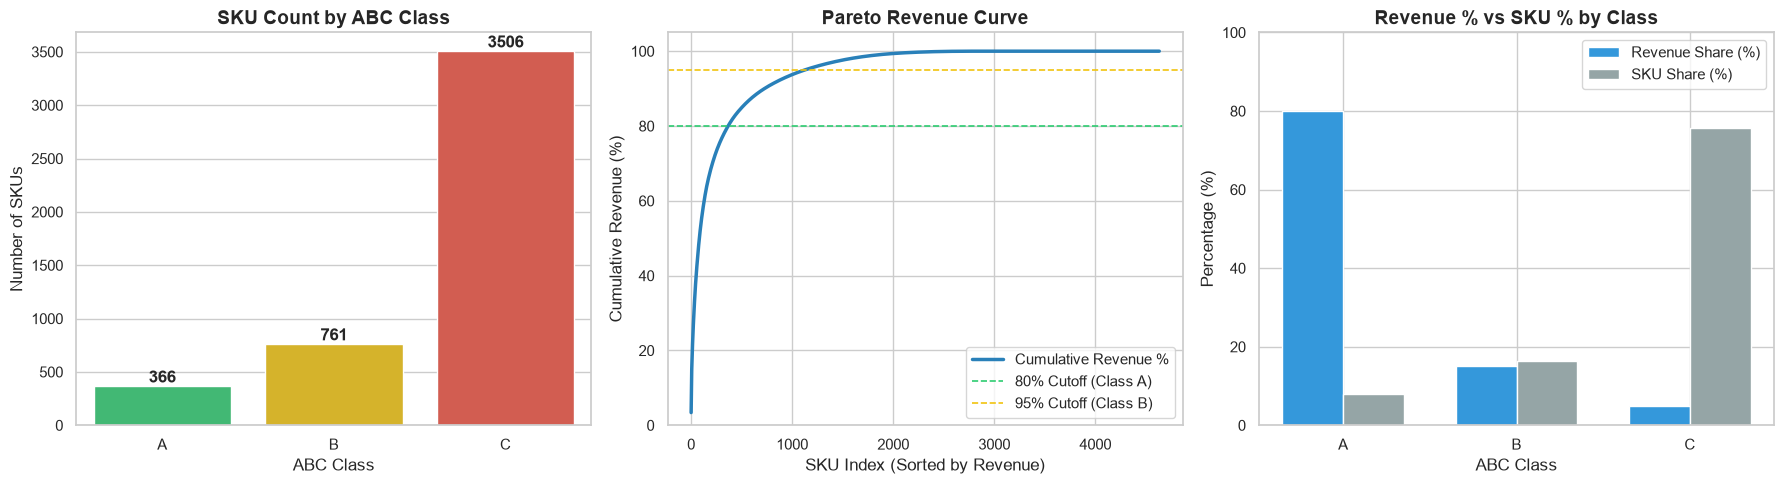

In [76]:
# Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ABC Classification Distribution (Count of SKUs)
abc_counts = inventory["ABC_Class"].value_counts().reindex(["A", "B", "C"])
palette = {"A": "#2ecc71", "B": "#f1c40f", "C": "#e74c3c"}

sns.barplot(
    x=abc_counts.index,
    y=abc_counts.values,
    palette=palette,
    ax=axes[0],
    hue=abc_counts.index,
    legend=False,
)
axes[0].set_title("SKU Count by ABC Class", fontsize=14, fontweight="bold")
axes[0].set_xlabel("ABC Class", fontsize=12)
axes[0].set_ylabel("Number of SKUs", fontsize=12)
for i, v in enumerate(abc_counts.values):
    axes[0].text(i, v + (max(abc_counts.values) * 0.01), str(v), ha="center", fontweight="bold")

# 2. Cumulative Revenue Curve (Lorenz Curve / Pareto Analysis)
axes[1].plot(
    range(len(inventory)),
    inventory["CumulativeRevenuePercentage"],
    color="#2980b9",
    linewidth=2.5,
    label="Cumulative Revenue %",
)
axes[1].axhline(80, color="#2ecc71", linestyle="--", linewidth=1.2, label="80% Cutoff (Class A)")
axes[1].axhline(95, color="#f1c40f", linestyle="--", linewidth=1.2, label="95% Cutoff (Class B)")
axes[1].set_title("Pareto Revenue Curve", fontsize=14, fontweight="bold")
axes[1].set_xlabel("SKU Index (Sorted by Revenue)", fontsize=12)
axes[1].set_ylabel("Cumulative Revenue (%)", fontsize=12)
axes[1].set_ylim(0, 105)
axes[1].legend(loc="lower right")

# 3. Revenue Share vs SKU Share Breakdown
class_summary = inventory.groupby("ABC_Class", observed=False).agg(
    RevenueShare=("TotalRevenue", "sum"),
    SKUShare=("StockCode", "count")
)
class_summary["RevenueShare"] = (class_summary["RevenueShare"] / inventory["TotalRevenue"].sum()) * 100
class_summary["SKUShare"] = (class_summary["SKUShare"] / len(inventory)) * 100
class_summary = class_summary.reindex(["A", "B", "C"])

x = range(len(class_summary))
bar_width = 0.35

axes[2].bar([i - bar_width/2 for i in x], class_summary["RevenueShare"], width=bar_width, label="Revenue Share (%)", color="#3498db")
axes[2].bar([i + bar_width/2 for i in x], class_summary["SKUShare"], width=bar_width, label="SKU Share (%)", color="#95a5a6")
axes[2].set_xticks(list(x))
axes[2].set_xticklabels(class_summary.index)
axes[2].set_title("Revenue % vs SKU % by Class", fontsize=14, fontweight="bold")
axes[2].set_xlabel("ABC Class", fontsize=12)
axes[2].set_ylabel("Percentage (%)", fontsize=12)
axes[2].set_ylim(0, 100)
axes[2].legend()

plt.tight_layout()
plt.show()

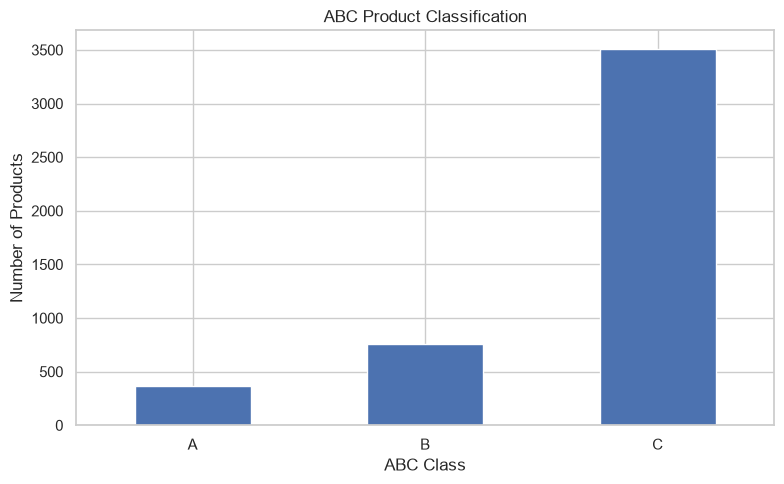

In [77]:
# ABC distribution

abc_counts = (
    inventory_final["ABC_Class"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

abc_counts.plot(kind="bar")

plt.title("ABC Product Classification")
plt.xlabel("ABC Class")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "abc_product_distribution.png",
    dpi=150
)

plt.show()



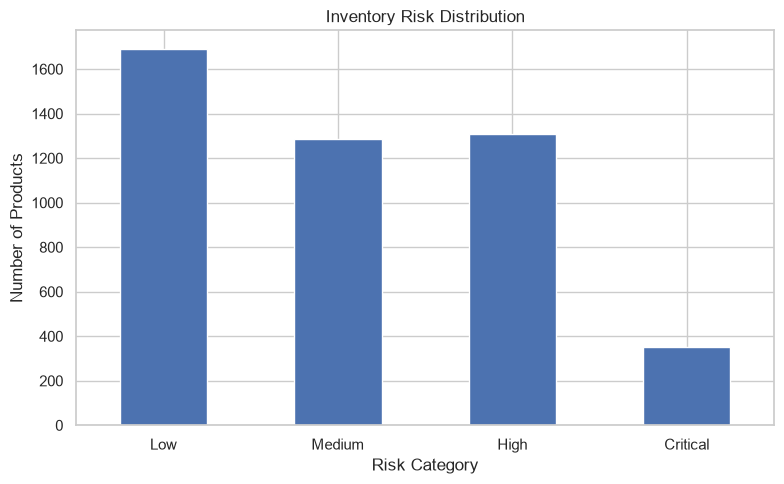

In [78]:
# Risk Distribution

risk_counts = (
    inventory_final["InventoryRiskCategory"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High", "Critical"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 5))

risk_counts.plot(kind="bar")

plt.title("Inventory Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "inventory_risk_distribution.png",
    dpi=150
)

plt.show()


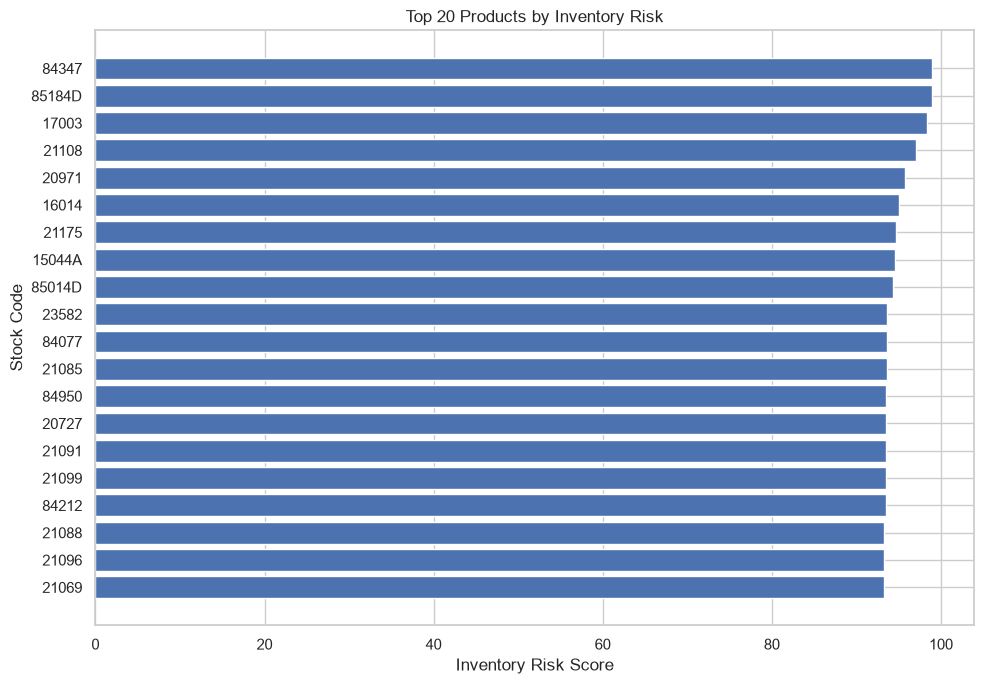

In [79]:
## Top 20 risky products

top_risk = (
    inventory_final
    .head(20)
    .sort_values("InventoryRiskScore")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_risk["StockCode"].astype(str),
    top_risk["InventoryRiskScore"]
)

plt.title("Top 20 Products by Inventory Risk")
plt.xlabel("Inventory Risk Score")
plt.ylabel("Stock Code")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_20_inventory_risk_products.png",
    dpi=150
)

plt.show()

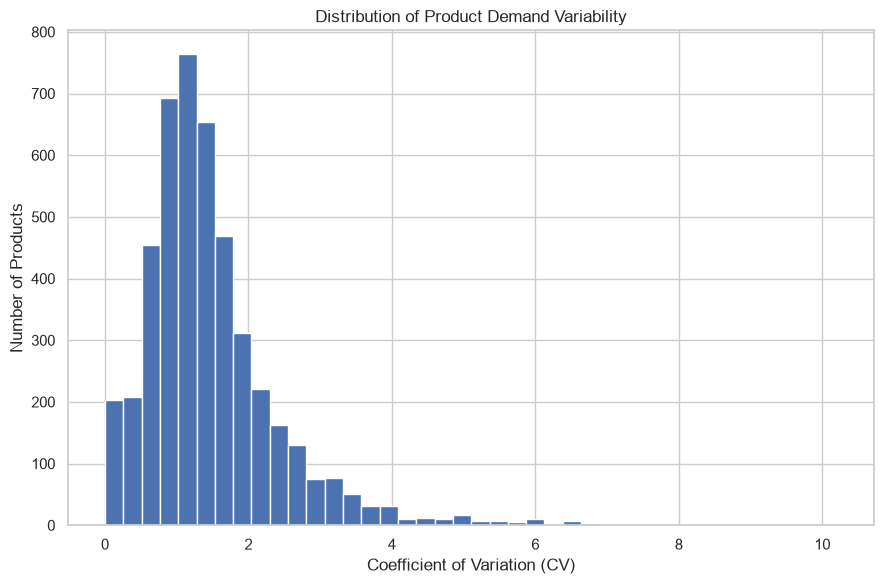

In [80]:
## Demand Variability Distribution

plt.figure(figsize=(9, 6))

plt.hist(
    inventory_final["DemandCV"],
    bins=40
)

plt.title("Distribution of Product Demand Variability")
plt.xlabel("Coefficient of Variation (CV)")
plt.ylabel("Number of Products")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "demand_variability_distribution.png",
    dpi=150
)

plt.show()

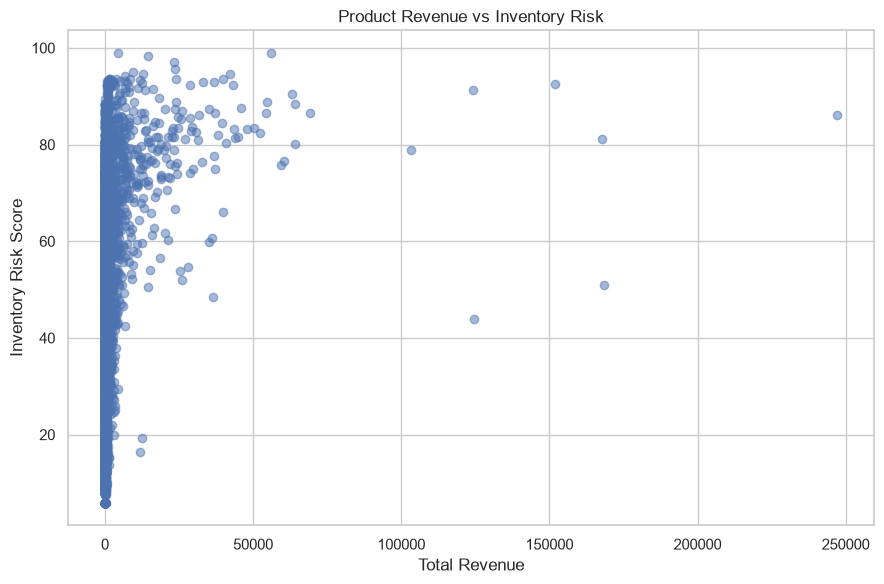

In [81]:
## Revenue vs Inventory Risk

plt.figure(figsize=(9, 6))

plt.scatter(
    inventory_final["TotalRevenue"],
    inventory_final["InventoryRiskScore"],
    alpha=0.5
)

plt.title("Product Revenue vs Inventory Risk")
plt.xlabel("Total Revenue")
plt.ylabel("Inventory Risk Score")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "revenue_vs_inventory_risk.png",
    dpi=150
)

plt.show()

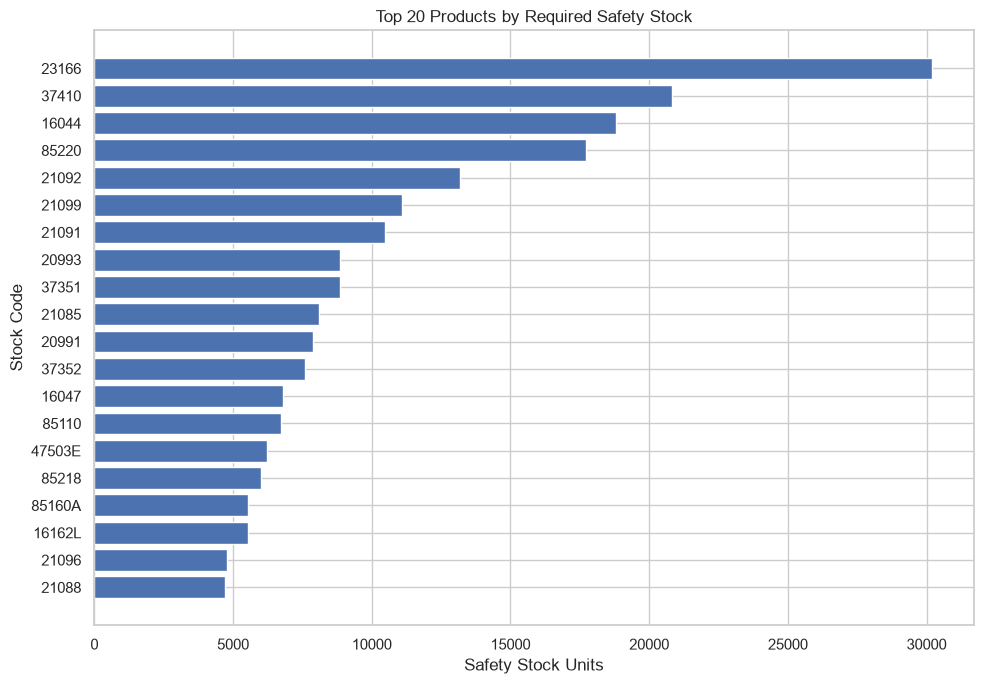

In [82]:
## Safety Stock analysis

top_safety_stock = (
    inventory_final
    .nlargest(20, "SafetyStock")
    .sort_values("SafetyStock")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_safety_stock["StockCode"].astype(str),
    top_safety_stock["SafetyStock"]
)

plt.title("Top 20 Products by Required Safety Stock")
plt.xlabel("Safety Stock Units")
plt.ylabel("Stock Code")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_safety_stock_products.png",
    dpi=150
)

plt.show()

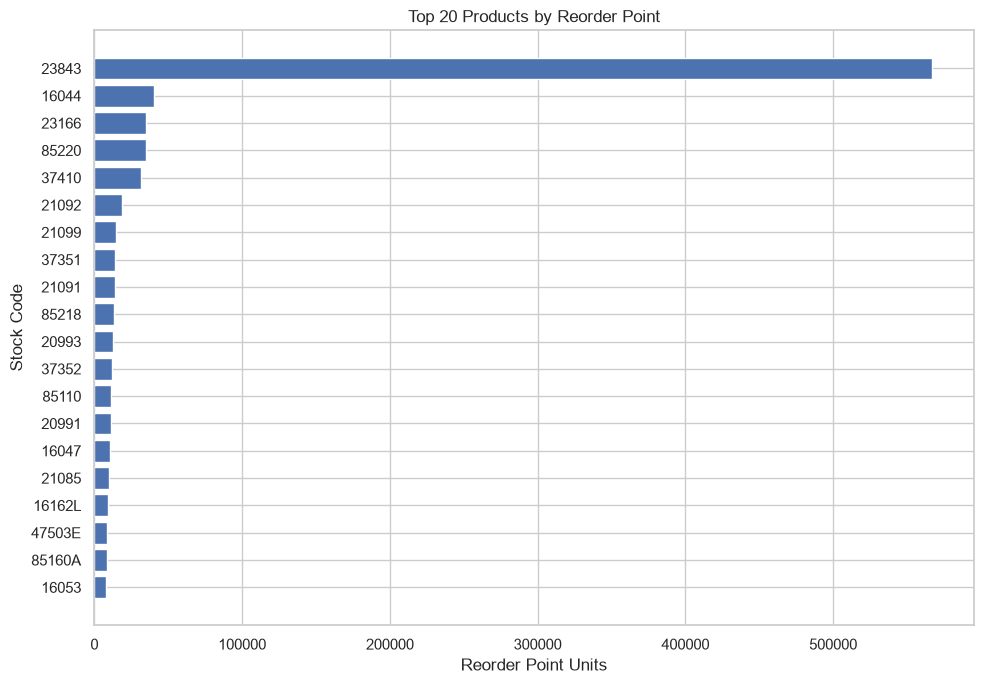

In [83]:
## Reorder point analysis

top_reorder = (
    inventory_final
    .nlargest(20, "ReorderPoint")
    .sort_values("ReorderPoint")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_reorder["StockCode"].astype(str),
    top_reorder["ReorderPoint"]
)

plt.title("Top 20 Products by Reorder Point")
plt.xlabel("Reorder Point Units")
plt.ylabel("Stock Code")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_reorder_point_products.png",
    dpi=150
)

plt.show()

In [84]:
## Inventory KPI summary

total_products = inventory_final["StockCode"].nunique()

critical_products = (
    inventory_final["InventoryRiskCategory"]
    .eq("Critical")
    .sum()
)

high_risk_products = (
    inventory_final["InventoryRiskCategory"]
    .eq("High")
    .sum()
)

average_risk = (
    inventory_final["InventoryRiskScore"].mean()
)

total_safety_stock = (
    inventory_final["SafetyStock"].sum()
)

total_reorder_requirement = (
    inventory_final["ReorderPoint"].sum()
)

print("========== INVENTORY KPI SUMMARY ==========")
print(f"Total Products: {total_products:,}")
print(f"Critical Risk Products: {critical_products:,}")
print(f"High Risk Products: {high_risk_products:,}")
print(f"Average Inventory Risk Score: {average_risk:.2f}")
print(f"Total Safety Stock Requirement: {total_safety_stock:,.2f}")
print(f"Total Reorder Point Units: {total_reorder_requirement:,.2f}")

========== INVENTORY KPI SUMMARY ==========
Total Products: 4,633
Critical Risk Products: 350
High Risk Products: 1,310
Average Inventory Risk Score: 48.58
Total Safety Stock Requirement: 881,486.34
Total Reorder Point Units: 2,175,113.04


In [85]:
## Top critical products

critical_products_table = (
    inventory_final[
        inventory_final["InventoryRiskCategory"] == "Critical"
    ]
    .head(20)
)

critical_products_table[
    [
        "StockCode",
        "ABC_Class",
        "AverageDailyDemand",
        "DemandCV",
        "SafetyStock",
        "ReorderPoint",
        "InventoryRiskScore"
    ]
]

,StockCode,ABC_Class,AverageDailyDemand,DemandCV,SafetyStock,ReorderPoint,InventoryRiskScore
0,84347,A,138.86,5.136856,3114.01,4086.06,98.96
1,85184D,A,176.47,4.542751,3499.60,4734.87,98.89
2,17003,A,260.53,3.360027,3821.47,5645.16,98.33
3,21108,A,49.93,5.619827,1224.91,1574.40,97.08
4,20971,A,45.35,3.648738,722.42,1039.90,95.71
5,16014,A,341.33,2.219425,3307.06,5696.34,95.05
6,21175,A,40.46,3.370691,595.33,878.53,94.63
7,15044A,A,31.37,8.947057,1225.33,1444.93,94.60
8,85014D,A,39.83,3.264881,567.74,846.57,94.28
9,23582,A,113.69,2.121744,1053.07,1848.92,93.67


In [86]:
## High priority products

reorder_priority = inventory_final[
    inventory_final["InventoryStatus"].isin(
        ["Urgent Review", "Reorder Priority"]
    )
].copy()

reorder_priority = reorder_priority.sort_values(
    "InventoryRiskScore",
    ascending=False
)

reorder_priority.head(20)

,StockCode,TotalDemand,AverageDailyDemand,DemandStdDev,DemandCV,DemandVariability,TotalRevenue,RevenuePercentage,CumulativeRevenuePercentage,ABC_Class,LeadTimeDemand,SafetyStock,ReorderPoint,RecommendedStockLevel,RecommendedOrderQuantity,InventoryRiskScore,InventoryRiskCategory,InventoryStatus
0,84347,28606,138.86,713.32,5.136856,Very High,55880.17,0.767513,20.932542,A,972.05,3114.01,4086.06,4087.0,973,98.96,Critical,Urgent Review
1,85184D,8294,176.47,801.65,4.542751,Very High,4445.14,0.061054,76.020889,A,1235.28,3499.60,4734.87,4735.0,1236,98.89,Critical,Urgent Review
2,17003,70082,260.53,875.38,3.360027,Very High,14640.96,0.201093,55.984072,A,1823.70,3821.47,5645.16,5646.0,1824,98.33,Critical,Urgent Review
3,21108,12532,49.93,280.59,5.619827,Very High,23322.62,0.320336,45.839958,A,349.50,1224.91,1574.40,1575.0,350,97.08,Critical,Urgent Review
4,20971,20500,45.35,165.48,3.648738,Very High,23554.30,0.323518,44.554363,A,317.48,722.42,1039.90,1040.0,318,95.71,Critical,Urgent Review
5,16014,29354,341.33,757.55,2.219425,Very High,9512.68,0.130657,64.242715,A,2389.28,3307.06,5696.34,5697.0,2390,95.05,Critical,Urgent Review
6,21175,20229,40.46,136.37,3.370691,Very High,42059.24,0.577683,28.108732,A,283.21,595.33,878.53,879.0,284,94.63,Critical,Urgent Review
7,15044A,4894,31.37,280.69,8.947057,Very High,12803.78,0.175860,59.361141,A,219.60,1225.33,1444.93,1445.0,220,94.60,Critical,Urgent Review
8,85014D,1912,39.83,130.05,3.264881,Very High,6607.60,0.090755,70.225507,A,278.83,567.74,846.57,847.0,279,94.28,Critical,Urgent Review
9,23582,4434,113.69,241.23,2.121744,Very High,8508.22,0.116860,65.491762,A,795.85,1053.07,1848.92,1849.0,796,93.67,Critical,Urgent Review


In [87]:
## Save priority products

priority_output_path = (
    PROCESSED_DIR / "inventory_priority_products.csv"
)

reorder_priority.to_csv(
    priority_output_path,
    index=False
)

print(f"Saved: {priority_output_path}")

Saved: ..\data\processed\inventory_priority_products.csv


In [88]:
# Create metadata

# This will be useful later for the API, dashboard, and MLflow.  


metadata = {
    "project": "RetailPulse",
    "step": "08",
    "module": "Inventory Optimization",
    "lead_time_days": LEAD_TIME_DAYS,
    "service_level_z": SERVICE_LEVEL_Z,
    "review_period_days": REVIEW_PERIOD_DAYS,
    "total_products": int(total_products),
    "critical_products": int(critical_products),
    "high_risk_products": int(high_risk_products),
    "average_inventory_risk_score": round(
        float(average_risk), 2
    ),
    "total_safety_stock": round(
        float(total_safety_stock), 2
    ),
    "total_reorder_point": round(
        float(total_reorder_requirement), 2
    )
}

metadata_path = OUTPUTS_DIR / "inventory_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

print(f"Saved metadata to: {metadata_path}")

Saved metadata to: ..\reports\outputs\inventory_metadata.json


In [93]:
output_dir = inventory_output_path.parent
print("Output directory:", output_dir)
print("Files created:")
for file in output_dir.iterdir():
    print(" -", file.name)

Output directory: ..\data\processed
Files created:
 - abc_product_analysis.csv
 - churn_feature_importance.csv
 - churn_model_comparison.csv
 - cluster_summary.csv
 - customer_churn_predictions.csv
 - customer_clusters.csv
 - customer_features.csv
 - daily_sales_features.csv
 - feature_engineered_sales.csv
 - forecast_model_evaluation.csv
 - inventory_optimization.csv
 - inventory_priority_products.csv
 - inventory_risk_summary.csv
 - monthly_revenue_forecast.csv
 - monthly_sales_features.csv
 - product_daily_demand.csv
 - product_features.csv
 - retail_clean.csv
 - retail_sales.csv
 - revenue_forecast_90_days.csv
 - rfm_customer_segments.csv
 - rfm_segment_summary.csv


In [94]:
risk_output_path = inventory_output_path.parent / "inventory_risk_summary.csv"

In [ ]:
## final verification

print("========== STEP 8 VERIFICATION ==========")

print(
    "Inventory optimization:",
    inventory_output_path.exists()
)

print(
    "ABC analysis:",
    abc_output_path.exists()
)

print(
    "Risk summary:",
    risk_output_path.exists()
)

print(
    "Priority products:",
    priority_output_path.exists()
)

print(
    "Metadata:",
    metadata_path.exists()
)

========== STEP 8 VERIFICATION ==========
Inventory optimization: True
ABC analysis: True
Risk summary: True
Priority products: True
Metadata: True
